In [15]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:
!pip install fastdtw
from sklearn.model_selection import train_test_split
import torch
from tqdm import tqdm
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torch.nn.functional as F
import pandas as pd
from scipy.spatial.distance import euclidean
import numpy as np
import time
import matplotlib.pyplot as plt

In [17]:
%load_ext autoreload
class CNN_GRU_Model(nn.Module):
    def __init__(self, time_lag=72, pred_horizon=4, num_stations=9):
        super(CNN_GRU_Model, self).__init__()

        self.pred_horizon = pred_horizon
        self.num_stations = num_stations

        # 3D Convolution Layer
        cnn_out_channels = 64
        self.conv3d = nn.Conv3d(in_channels=1, out_channels=cnn_out_channels, kernel_size=(1, 4, 1))
        self.activation = nn.SELU()

        # GRU Layer
        hidden_size=32 * num_stations * pred_horizon
        self.gru = nn.GRU(input_size=num_stations*cnn_out_channels, hidden_size=hidden_size, num_layers=2, batch_first=True, dropout=0.02)

        # Fully connected layer for main model output
        fc_main_output_size = 250
        self.fc_main = nn.Linear(hidden_size, fc_main_output_size)

        # Fully connected layer for auxiliary input (72, 3) -> flattened and mapped to 100 neurons
        aux_data_len=3
        fc_aux_output_size=100
        self.fc_aux = nn.Linear(time_lag * aux_data_len, fc_aux_output_size)

        # Fully connected layer after concatenating the main and aux inputs
        fc_concat1_output_size = 80
        self.fc_concat1 = nn.Linear(fc_main_output_size+fc_aux_output_size, fc_concat1_output_size)
        self.fc_concat2 = nn.Linear(fc_concat1_output_size, num_stations * pred_horizon)

    def forward(self, x, aux_input):
        # Main model (CNN + GRU)
        x = x.unsqueeze(1)  # Shape: (batch_size, 1, 9, 4, 12)
        x = self.conv3d(x)  # Shape: (batch_size, 64, 9, 1, 12)
        x = self.activation(x)
        x = x.permute(0, 4, 1, 2, 3).contiguous()  # Shape: (batch_size, 12, 64, 9, 1)
        x = x.view(x.size(0), x.size(1), -1)  # Shape: (batch_size, 12, 64 * 9)
        x, _ = self.gru(x)  # Shape: (batch_size, time_lag, hidden_size)
        x = x[:, -1, :]  # Take the last time step's output -> Shape: (batch_size, hidden_size)
        x = self.fc_main(x)  # Shape: (batch_size, 250)

        # Auxiliary input processing (flatten first)
        aux_input = aux_input.view(aux_input.size(0), -1)  # Flatten (batch_size, 72 * 3)
        aux_out = self.fc_aux(aux_input)  # Shape: (batch_size, 100)
        aux_out = self.activation(aux_out)

        # Concatenate the main model output and auxiliary input
        combined = torch.cat((x, aux_out), dim=1)  # Shape: (batch_size, 250 + 100)

        # Final fully connected layer to get output (batch_size, 9 * 5)
        output = self.fc_concat1(combined)  # Shape: (batch_size, 9 * 5)
        output = self.activation(output)
        output = self.fc_concat2(output)
        output = output.view(output.size(0), self.num_stations, self.pred_horizon)  # Reshape to (batch_size, 9, 5)

        return output

    def train_model_early_stop(self, num_epochs, train_loader, valid_loader, batch_size, optimizer, criterion, device, patience=7):
        last_valid_loss = float('inf')
        epochs_no_improve = 0
        early_stop = False

        train_loss_history = []
        val_loss_history = []
        start_time = time.time()
        trained_epochs = 0

        for epoch in range(num_epochs):
            if early_stop:
                break

            trained_epochs += 1
            train_epoch_iterator = tqdm(train_loader, desc="Training")
            epoch_loss = self.train_epoch(train_epoch_iterator, optimizer, criterion, device)
            val_loss = self.get_eval_factors(valid_loader, batch_size, criterion, device)

            train_loss_history += [epoch_loss]
            val_loss_history += [val_loss]

            print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {epoch_loss:.4f}, Val Loss: {val_loss:.4f}')

        # Early stopping
            if val_loss < last_valid_loss:
                last_valid_loss = val_loss
                epochs_no_improve = 0
                best_model_wts = self.state_dict()
            else:
                epochs_no_improve += 1

            if epochs_no_improve >= patience:
                print(f'Early stopping triggered after {epoch+1} epochs')
                early_stop = True

        end_time = time.time()
        training_time = end_time - start_time
        print(f'Total Training Time: {training_time:.2f} seconds')

        if early_stop:
            self.load_state_dict(best_model_wts)

        return (train_loss_history, val_loss_history, trained_epochs)

    def train_epoch(self, train_loader, optimizer, criterion, device):
        self.train()
        running_loss = 0.0
        total_samples = 0

        for inputs, aux_inputs, targets in train_loader:
            inputs, aux_inputs, targets = inputs.to(device), aux_inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = self(inputs, aux_inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * targets.size(0)
            total_samples += targets.size(0)
            train_loader.set_postfix({'train loss': loss.item()})

        epoch_loss = running_loss / total_samples
        return epoch_loss

    def get_eval_factors(self, val_loader, batch_size, criterion, device):
        self.eval()
        total_loss = 0
        total_samples = 0

        with torch.no_grad():
            for inputs, aux_inputs, targets in val_loader:
                inputs, aux_inputs, targets = inputs.to(device), aux_inputs.to(device), targets.to(device)
                outputs = model(inputs, aux_inputs)
                loss = criterion(outputs, targets)

                total_loss += loss.item() * targets.size(0)
                total_samples += targets.size(0)

        val_loss = total_loss / total_samples

        return val_loss

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [18]:
def calculate_dtw(df1, df2):
    series1 = df1.to_numpy()
    series2 = df2.to_numpy()

    distance, _ = fastdtw(series1, series2, dist=euclidean)
    return distance

def append_time_if_missing(date_str):
    if len(date_str) == 10:  # 'yy-mm-dd' has a length of 10
        return date_str + ' 00:00:00'
    else:
        return date_str

def prepare_data(r=12, b=5):
  pm25_data = df['PM2.5'].values
  station_counts = df['Station'].value_counts().reindex(range(1, 10), fill_value=0)
  total_data = station_counts[1]

  inputs = []
  outputs = []
  aux_inputs = []

  aux_data = []

  for index, row in aux_df.iterrows():
    row_values = row.tolist()
    aux_data.append(row_values[1:])

  print(len(aux_data))
  print(total_data)

  for i in range(0, total_data - r - b + 1, 2):
      input = []
      output = []
      for j in range(9):
        inp = []
        out = []
        np.append(similars[j],j + 1)
        for k in similars[j]:
          inp.append(pm25_data[(k - 1) * total_data + i:(k - 1) * total_data + i + r])
          out.append(pm25_data[(k - 1) * total_data + i + r:(k - 1) * total_data + i + r + b])
        input.append(inp)
        output.append(out[-1])
      inputs.append(input)
      outputs.append(output)
      aux_slice = aux_data[i:i + r]  # Get slice of aux_data
      aux_inputs.append(np.array(aux_slice))

  inputs = np.array(inputs)
  outputs = np.array(outputs)
  aux_inputs = np.array(aux_inputs)
  return inputs, outputs, aux_inputs

In [19]:
df =  pd.read_csv('/content/drive/MyDrive/Air Polution Research/preprocessed_data.csv')

similars_df = pd.read_csv('/content/drive/MyDrive/Air Polution Research/similars.csv')
similars = similars_df.to_numpy()
df = df.sort_values(by=['Station', 'Date'], ascending=[True, True])

aux_df = pd.read_csv('/content/drive/MyDrive/Air Polution Research/IsfMet.csv')
aux_df['date'] = aux_df['date'].apply(append_time_if_missing)
filtered_aux_df = aux_df[aux_df['date'].isin(df['Date'])]
filtered_aux_df = filtered_aux_df[['date', 'ws', 'wd', 'air_temp']]
aux_df = filtered_aux_df
aux_df = aux_df.fillna(method='ffill').fillna(method='bfill')

<ipython-input-19-fe108d292131>:12: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  aux_df = aux_df.fillna(method='ffill').fillna(method='bfill')


In [20]:
time_lag = 72
pred_horizon = 4
num_epochs = 20
batch_size = 32

In [21]:
inputs, outputs, aux = prepare_data(r = time_lag, b = pred_horizon)

combined = list(zip(inputs, aux, outputs))

train_data, temp_data = train_test_split(combined, test_size=0.4, random_state=42)

val_data, test_data = train_test_split(temp_data, test_size=0.5, random_state=42)

X_train, aux_train, y_train = zip(*train_data)
X_val, aux_val, y_val = zip(*val_data)
X_test, aux_test, y_test = zip(*test_data)

print(X_train[0].shape, aux_train[0].shape)

23470
23470
(9, 4, 72) (72, 3)


In [22]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
aux_train_tensor = torch.tensor(aux_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
aux_val_tensor = torch.tensor(aux_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

# Create TensorDataset and DataLoader for training and validation
train_dataset = TensorDataset(X_train_tensor, aux_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, aux_val_tensor, y_val_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [23]:
# Define model, loss function, and optimizer
model = CNN_GRU_Model(time_lag=time_lag, pred_horizon=pred_horizon)
criterion = nn.MSELoss()  # For regression
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [24]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)
print(device)

cuda


In [25]:
(train_loss_history, val_loss_history, trained_epochs) = model.train_model_early_stop(num_epochs, train_loader, val_loader,
                                                                                      batch_size, optimizer, criterion, device, patience=3)

Training: 100%|██████████| 220/220 [00:14<00:00, 14.94it/s, train loss=1.75e+4]


Epoch [1/20], Train Loss: 11680.2880, Val Loss: 10342.6420


Training: 100%|██████████| 220/220 [00:13<00:00, 16.41it/s, train loss=5.68e+3]


Epoch [2/20], Train Loss: 9079.5743, Val Loss: 9119.3458


Training: 100%|██████████| 220/220 [00:13<00:00, 16.34it/s, train loss=2.81e+4]


...

Training: 100%|██████████| 220/220 [00:13<00:00, 15.89it/s, train loss=1.06e+4]


Epoch [19/20], Train Loss: 7227.6750, Val Loss: 11622.8305


Training: 100%|██████████| 220/220 [00:13<00:00, 15.94it/s, train loss=1.09e+4]


Epoch [20/20], Train Loss: 8920.1719, Val Loss: 10338.8035
Early stopping triggered after 20 epochs
Total Training Time: 306.90 seconds


([11680.287991314744,
  9079.574326870414,
  8322.988708443912,
  8005.74803810848,
  7661.3083539752415,
  7907.9211020503635,
  7359.574927655337,
  6997.635810371545,
  6900.209225210786,
  6426.451555218918,
  6481.450826919395,
  7466.301493060117,
  6936.195304150933,
  9173.685480030284,
  7010.451135730499,
  10502.050498042701,
  9913.710688419511,
  7428.485801368468,
  7227.675040966087,
  8920.171878617928],
 [10342.642046440973,
  9119.345816639958,
  8813.161943275909,
  8180.670162259616,
  7813.783213141026,
  8126.095306657318,
  8121.804676649305,
  7835.028695913462,
  7238.237717848558,
  7801.864619224092,
  7598.435544370994,
  8960.344820880075,
  7223.202662593483,
  10617.78351028312,
  8230.623840645032,
  11789.359309895834,
  8537.072898303953,
  7429.88562366453,
  11622.830467080663,
  10338.803545673078],
 20)

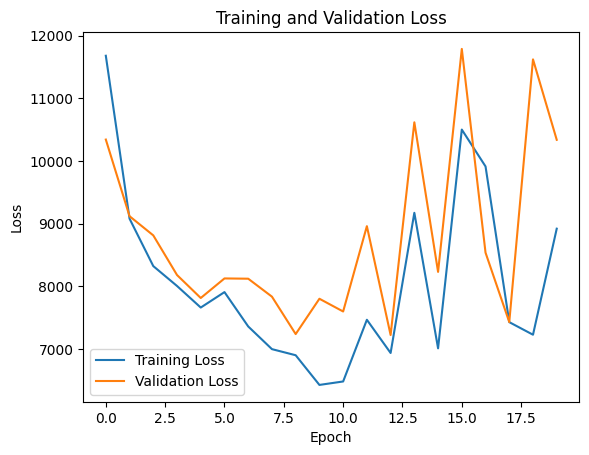

In [32]:
plt.figure()
plt.plot(train_loss_history, label='Training Loss')
plt.plot(val_loss_history, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

# Show the plot
plt.show()

In [40]:
model.eval()

aux_single = aux_train[0]
single_input = X_train[0]  # Shape: (9, 4, 12)
aux_single = torch.tensor(aux_single, dtype=torch.float32)
single_input = torch.tensor(single_input, dtype=torch.float32)

# Add a batch dimension since the model expects a batch
aux_single = aux_single.unsqueeze(0)  # Shape: (1, 9, 4, 12)
single_input = single_input.unsqueeze(0)  # Shape: (1, 9, 4, 12)

# Make sure no gradients are computed during inference
aux_single = aux_single.to(device)
single_input = single_input.to(device)
with torch.no_grad():
    prediction = model(single_input, aux_single)

# `prediction` now contains the output for this single input
print("Prediction:", prediction)
print("Real:", y_train[0])

Prediction: tensor([[[34.7745, 34.9856, 33.0783, 33.4352],
         [35.7793, 32.0249, 33.4342, 29.6585],
         [46.9887, 45.4674, 44.1876, 41.3328],
         [75.3428, 66.9432, 72.4125, 74.1891],
         [42.4163, 42.2515, 45.5498, 45.0072],
         [34.5540, 30.3566, 27.6666, 35.0849],
         [44.5699, 42.0271, 42.2715, 43.8643],
         [73.2291, 65.5739, 68.8562, 71.1604],
         [72.1535, 72.9273, 72.5454, 70.0277]]], device='cuda:0')
Real: [[ 95.   109.   111.   104.  ]
 [ 95.   109.   111.   104.  ]
 [ 79.   107.   106.   118.  ]
 [136.   123.   108.    92.  ]
 [ 84.84  88.94  92.3   93.95]
 [ 95.   109.   111.   104.  ]
 [ 97.27  98.14  95.94 106.55]
 [136.   123.   108.    92.  ]
 [136.   123.   108.    92.  ]]
